<a href="https://colab.research.google.com/github/nwaryszak/APRAU/blob/Kacper/APRAU_Step1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kacper Branch

1. IMPORT LIBRARIES AND LOADING DATA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, LeaveOneOut, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.utils import resample

# Ustawienie stałego ziarna losowości dla powtarzalności wyników
RANDOM_STATE = 42

# 1. Wczytanie danych
df = pd.read_csv('dataset_grupo_06.csv')

# 2. Usunięcie zmiennej regresyjnej (unikamy Data Leakage)
X = df.drop(columns=['target_class', 'target_regression'])
y = df['target_class']

print(f"Kształt macierzy cech X: {X.shape}")
print(f"Rozkład klas docelowych:\n{y.value_counts()}")

Kształt macierzy cech X: (2000, 33)
Rozkład klas docelowych:
target_class
HT          1131
HT_HY        481
DI_HT_HY     388
Name: count, dtype: int64


2. Definition od Preprocessing Pipeline & Avoidng Data Leakage

In [2]:
# Zidentyfikowanie typów kolumn
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Preprocessing: Skalowanie cech numerycznych i kodowanie kategorycznych
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
    ]
)

print(f"Liczba cech numerycznych: {len(num_cols)}")
print(f"Liczba cech kategorycznych: {len(cat_cols)}")

Liczba cech numerycznych: 21
Liczba cech kategorycznych: 12


3.

In [3]:
# Słownik do przechowywania zagregowanych wyników
resampling_results = {}

# 1. HOLDOUT (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

lda_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', LinearDiscriminantAnalysis())
])

lda_pipeline.fit(X_train, y_train)
y_pred_holdout = lda_pipeline.predict(X_test)

resampling_results['Holdout'] = {
    'Accuracy (mean)': accuracy_score(y_test, y_pred_holdout),
    'Accuracy (std)': 0.0,
    'Macro F1 (mean)': f1_score(y_test, y_pred_holdout, average='macro'),
    'Macro F1 (std)': 0.0
}

# 2. 5-FOLD CROSS-VALIDATION
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores_5f = cross_validate(lda_pipeline, X, y, cv=cv5, scoring=['accuracy', 'f1_macro'])

resampling_results['5-Fold CV'] = {
    'Accuracy (mean)': np.mean(scores_5f['test_accuracy']),
    'Accuracy (std)': np.std(scores_5f['test_accuracy']),
    'Macro F1 (mean)': np.mean(scores_5f['test_f1_macro']),
    'Macro F1 (std)': np.std(scores_5f['test_f1_macro'])
}

# 3. 10-FOLD CROSS-VALIDATION
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scores_10f = cross_validate(lda_pipeline, X, y, cv=cv10, scoring=['accuracy', 'f1_macro'])

resampling_results['10-Fold CV'] = {
    'Accuracy (mean)': np.mean(scores_10f['test_accuracy']),
    'Accuracy (std)': np.std(scores_10f['test_accuracy']),
    'Macro F1 (mean)': np.mean(scores_10f['test_f1_macro']),
    'Macro F1 (std)': np.std(scores_10f['test_f1_macro'])
}

# 4. LEAVE-ONE-OUT (LOOCV)
loo = LeaveOneOut()
scores_loo = cross_validate(lda_pipeline, X, y, cv=loo, scoring=['accuracy'], n_jobs=-1)

resampling_results['LOOCV'] = {
    'Accuracy (mean)': np.mean(scores_loo['test_accuracy']),
    'Accuracy (std)': np.std(scores_loo['test_accuracy']),
    'Macro F1 (mean)': np.nan,  # F1 ma mały sens przy ocenie pojedynczej próbki per fold
    'Macro F1 (std)': np.nan
}

# 5. BOOTSTRAP (N=100 powtórzeń)
n_bootstraps = 100
boot_acc, boot_f1 = [], []

for i in range(n_bootstraps):
    X_boot, y_boot = resample(X_train, y_train, random_state=RANDOM_STATE + i, stratify=y_train)
    lda_pipeline.fit(X_boot, y_boot)
    y_boot_pred = lda_pipeline.predict(X_test)
    boot_acc.append(accuracy_score(y_test, y_boot_pred))
    boot_f1.append(f1_score(y_test, y_boot_pred, average='macro'))

resampling_results['Bootstrap (N=100)'] = {
    'Accuracy (mean)': np.mean(boot_acc),
    'Accuracy (std)': np.std(boot_acc),
    'Macro F1 (mean)': np.mean(boot_f1),
    'Macro F1 (std)': np.std(boot_f1)
}

# Wyświetlenie wyników w formie czytelnej tabeli
df_resampling = pd.DataFrame(resampling_results).T
print("=== PODSUMOWANIE METOD PONOWNEGO PRÓBKOWANIA DLA LDA ===")
display(df_resampling)

=== PODSUMOWANIE METOD PONOWNEGO PRÓBKOWANIA DLA LDA ===


,Accuracy (mean),Accuracy (std),Macro F1 (mean),Macro F1 (std)
Holdout,0.69000,0.000000,0.606861,0.000000
5-Fold CV,0.67700,0.021413,0.585121,0.025090
10-Fold CV,0.67750,0.016919,0.582240,0.019714
LOOCV,0.67500,0.468375,NaN,NaN
Bootstrap (N=100),0.68985,0.013289,0.611717,0.019222


4.

Łączna liczba cech po One-Hot Encoding: 43
Liczba cech wybranych przez Lasso (aktywnych): 29
Liczba cech wyzerowanych (odrzuconych) przez Lasso: 14


/tmp/ipykernel_713/3862786479.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_coefs.head(10), x='Lasso_Weight', y='Feature', palette='viridis')


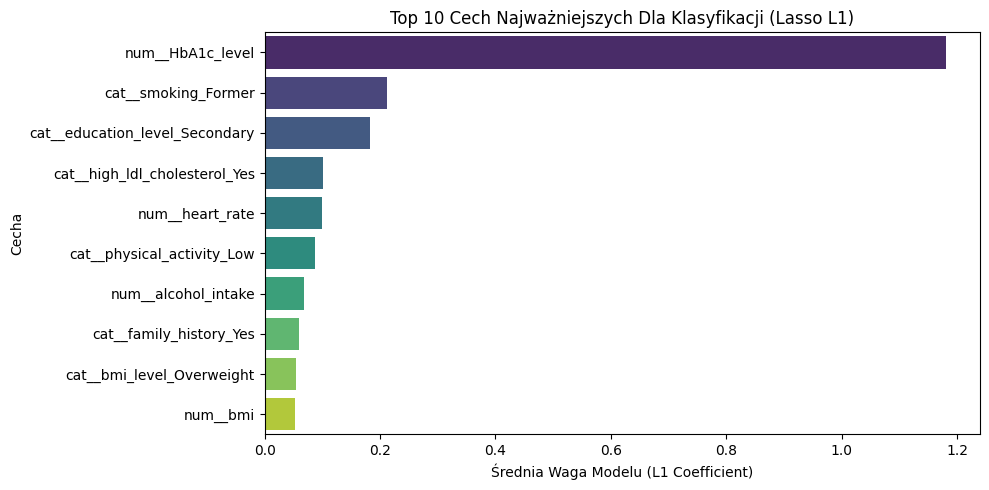

In [4]:
# 1. Model Bazowy (bez regularyzacji / L2 słaby)
base_lr = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty=None, max_iter=2000, random_state=RANDOM_STATE))
])

# 2. Model Ridge (L2 Penalty)
ridge_lr = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty='l2', C=0.1, max_iter=2000, random_state=RANDOM_STATE))
])

# 3. Model Lasso (L1 Penalty) - Selekcja Cech
lasso_lr = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(penalty='l1', solver='saga', C=0.1, max_iter=3000, random_state=RANDOM_STATE))
])

# Trening na zbiorze treningowym
base_lr.fit(X_train, y_train)
ridge_lr.fit(X_train, y_train)
lasso_lr.fit(X_train, y_train)

# Pobranie nazw przetworzonych cech
feature_names = lasso_lr.named_steps['prep'].get_feature_names_out()

# Wyciągnięcie istotności cech z Lasso (średnia bezwzględna wartość wag ze wszystkich klas)
lasso_coefs = np.mean(np.abs(lasso_lr.named_steps['model'].coef_), axis=0)

df_coefs = pd.DataFrame({
    'Feature': feature_names,
    'Lasso_Weight': lasso_coefs
}).sort_values(by='Lasso_Weight', ascending=False)

# Zliczenie odrzuconych cech przez Lasso
zero_features = df_coefs[df_coefs['Lasso_Weight'] == 0]
active_features = df_coefs[df_coefs['Lasso_Weight'] > 0]

print(f"Łączna liczba cech po One-Hot Encoding: {len(df_coefs)}")
print(f"Liczba cech wybranych przez Lasso (aktywnych): {len(active_features)}")
print(f"Liczba cech wyzerowanych (odrzuconych) przez Lasso: {len(zero_features)}")

# Wykres 10 najważniejszych cech wyselekcjonowanych przez Lasso
plt.figure(figsize=(10, 5))
sns.barplot(data=df_coefs.head(10), x='Lasso_Weight', y='Feature', palette='viridis')
plt.title('Top 10 Cech Najważniejszych Dla Klasyfikacji (Lasso L1)')
plt.xlabel('Średnia Waga Modelu (L1 Coefficient)')
plt.ylabel('Cecha')
plt.tight_layout()
plt.show()

5.

In [5]:
# Zbieranie metryk dla modeli regularyzacji
reg_results = []

models = {
    'Unregularized LR': base_lr,
    'Ridge (L2 Regularization)': ridge_lr,
    'Lasso (L1 Feature Selection)': lasso_lr
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    reg_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro'),
        'Macro Precision': precision_score(y_test, y_pred, average='macro'),
        'Macro Recall': recall_score(y_test, y_pred, average='macro')
    })

df_reg_comparison = pd.DataFrame(reg_results)
print("=== PORÓWNANIE REGULARYZACJI RIDGE I LASSO ===")
display(df_reg_comparison)

=== PORÓWNANIE REGULARYZACJI RIDGE I LASSO ===


,Model,Accuracy,Macro F1,Macro Precision,Macro Recall
0,Unregularized LR,0.7000,0.607219,0.645107,0.622454
1,Ridge (L2 Regularization),0.7125,0.602901,0.670166,0.623837
2,Lasso (L1 Feature Selection),0.7200,0.569905,0.633933,0.622677


6.

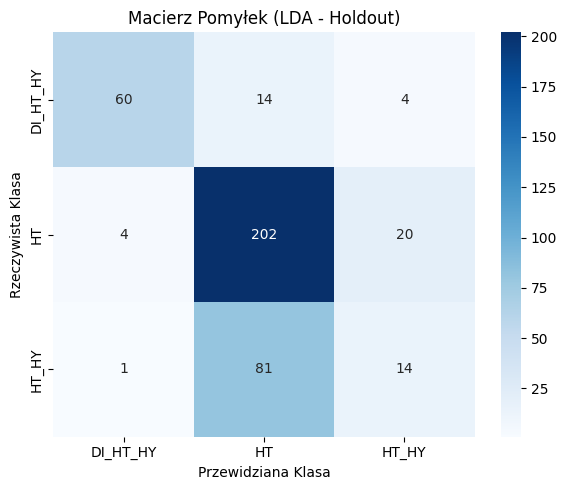

In [6]:
# Wykres Macierzy Pomyłek dla LDA na Holdoucie
cm = confusion_matrix(y_test, y_pred_holdout)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Macierz Pomyłek (LDA - Holdout)')
plt.xlabel('Przewidziana Klasa')
plt.ylabel('Rzeczywista Klasa')
plt.tight_layout()
plt.show()